## Simulação da ruína do jogador

Primeiro, definimos uma função `ruina(i, N, p)` que realiza uma partida, onde `i`, `N`, e `p` são o saldo inicial, o objetivo e a probabilidade de vitória, respectivamente. Começando o jogo com $i$ moedas no tempo $T = 0$, continuamos jogando enquanto $x \neq 0$ e $x \neq N$. Usamos o módulo `np.random.binomial(n, p)` para jogar a moeda uma vez (`n = 1` com probabilidade de vitória `p`). Essa função retorna o número de sucessos, neste caso, `0` ou `1`. Se retorna `1`, então adiciona 1 ao saldo. Caso contrário, subtrai 1. A função `ruina()` retorna dois valores: um booleano (`True` se o jogador atingiu `N` e `False` caso contrário) e o número de lançamentos da moeda.

In [1]:
import numpy as np

def ruina(i, N, p):
    x = i
    T = 0

    while x != 0 and x != N:
        passo = np.random.binomial(1, p)

        if passo == 1:
            x += 1
        else:
            x -= 1

        T += 1

    sucesso = (x == N)

    return sucesso, T

### Função que simula um jogo

Escrevemos a função `simulacao_ruina(i, N, p, n_sim)` que realiza a jogatina `n_sim` vezes e retorna a probabilidade de sucesso (a razão entre o número de sucessos e o número de simulações), o tempo médio de uma jogatina (a média do número de lançamentos de moeda entre todas as simulações) e o erro entre a probabilidade de sucesso exata e a observada nas simulações.

In [2]:
def simulacao_ruina(i, N, p, n_sim=1000):
    sucessos = 0
    tempos = []

    for _ in range(n_sim):
        sucesso, T = ruina(i, N, p)

        if sucesso:
            sucessos += 1

        tempos.append(T)

    prob_sucesso = sucessos / n_sim
    tempo_medio = np.mean(tempos)

    # calcula o erro entre a probabilidade da simulacao e a probabilidade exata (solucao da ruina)
    if p == 0.5:
        prob_exata = i/N
        erro = np.abs(prob_sucesso - prob_exata)
    else:
        q = 1 - p
        prob_exata = (1 - (q/p)**i) / (1 - (q/p)**N)
        erro = np.abs(prob_sucesso - prob_exata)

    return prob_sucesso, tempo_medio, erro

Realizamos uma jogatina, com saldo inicial $i=4$, objetivo $N=10$ e probabilidade de vitória $p=0.5$.

In [3]:
prob, tempo, erro = simulacao_ruina(i=4, N=10, p=0.5, n_sim=2000)

print("Probabilidade de sucesso:", prob)
print("Tempo médio:", tempo)
print(f"Erro: {erro:.2e}")

Probabilidade de sucesso: 0.391
Tempo médio: 23.348
Erro: 9.00e-03


### Simulação N=10, p=0.5, i=1:9

Agora, mantemos os parâmetros $N=10$ e $p=0.5$ e varremos $i$ (saldo inicial) de 1 a 9.

|   Saldo inicial |   Probabilidade de sucesso |   Tempo médio |     Erro |
|-----------------|----------------------------|---------------|----------|
|               1 |                     0.1035 |          8.99 | 3.50e-03 |
|               2 |                     0.1925 |         15.37 | 7.50e-03 |
|               3 |                     0.3050 |         21.21 | 5.00e-03 |
|               4 |                     0.4045 |         23.85 | 4.50e-03 |
|               5 |                     0.4935 |         25.22 | 6.50e-03 |
|               6 |                     0.6295 |         23.22 | 2.95e-02 |
|               7 |                     0.6825 |         21.76 | 1.75e-02 |
|               8 |                     0.8105 |         15.66 | 1.05e-02 |
|               9 |                     0.9070 |          8.62 | 7.00e-03 |


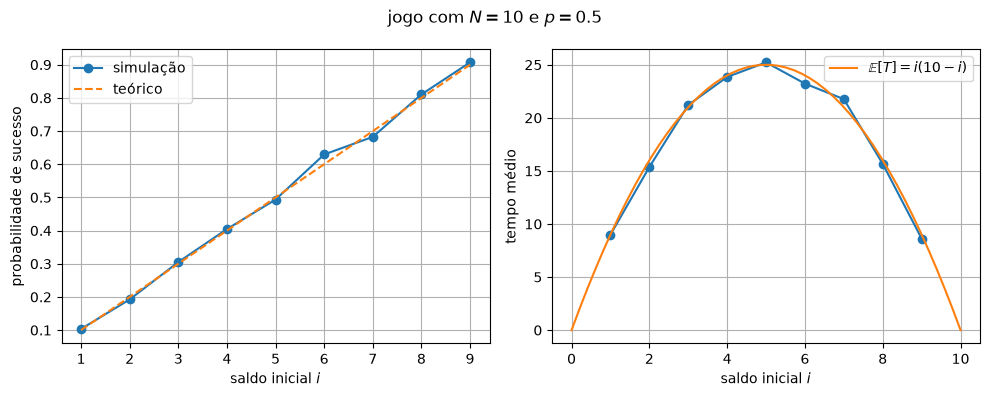

In [4]:
import tabulate
import matplotlib.pyplot as plt

N = 10
p = 0.5
q = 1 - p
dados = []

for i in range(1, 10):
    prob, tempo, erro = simulacao_ruina(i, N, p, n_sim=2000)
    dados.append([i, prob, tempo, erro])

print(tabulate.tabulate(dados, headers=['Saldo inicial', 'Probabilidade de sucesso', 'Tempo médio', 'Erro'], tablefmt='github', floatfmt=['','.4f', '.2f', '.2e']))

# extrai dados da tabela para plotar graficos
i = [linha[0] for linha in dados]
prob = [linha[1] for linha in dados]
tempo = [linha[2] for linha in dados]
erro = [linha[3] for linha in dados]

prob_exata = [i_val / 10 for i_val in i]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle(r'jogo com $N=10$ e $p=0.5$')

ax1.plot(i, prob, 'o-', label='simulação')
ax1.plot(i, prob_exata, '--', label='teórico')
ax1.set_xlabel('saldo inicial $i$')
ax1.set_ylabel('probabilidade de sucesso')
ax1.legend()
ax1.grid()

ii = np.linspace(0, 10)
ax2.plot(i, tempo, 'o-')
ax2.plot(ii, ii*(N-ii), label=r'$\mathbb{E}[T]=i(10-i)$')
ax2.set_xlabel('saldo inicial $i$')
ax2.set_ylabel('tempo médio')
ax2.grid()
ax2.legend()

plt.tight_layout()
plt.show()

### Conjectura da esperança para jogos simétricos

Do segundo gráfico, vemos que a esperança (ou o tempo médio) do tempo de parada se comporta como uma função quadrática do saldo inicial: uma parabóla com concavidade voltada para baixo que possui zeros em $i=0$ e $i=N$. Como $\mathbb{E}_0[T]=0$ e $\mathbb{E}_N[T]=0$, conjecturamos que, para $p=q=1/2$, deve valer $$\mathbb{E}[T]=i(N-i).$$ De fato, esse modelo fornece os valores $$9, 16, 21, 24, 25, 24, 21, 16, 9,$$ que estão de acordo com os resultados obtidos na simulação.

### Simulação N=10, p=0.3, i=1:9

Alterando a probabilidade de vitória para $p=0.3$, obtemos

|   Saldo inicial |   Probabilidade de sucesso |   Tempo médio |     Erro |
|-----------------|----------------------------|---------------|----------|
|               1 |                     0.0000 |          2.56 | 2.79e-04 |
|               2 |                     0.0010 |          5.01 | 7.07e-05 |
|               3 |                     0.0025 |          7.37 | 5.29e-05 |
|               4 |                     0.0065 |         10.01 | 5.11e-04 |
|               5 |                     0.0120 |         12.16 | 2.25e-03 |
|               6 |                     0.0270 |         14.20 | 6.53e-03 |
|               7 |                     0.0755 |         15.48 | 3.02e-03 |
|               8 |                     0.1830 |         15.57 | 5.03e-04 |
|               9 |                     0.4275 |         11.68 | 9.52e-04 |


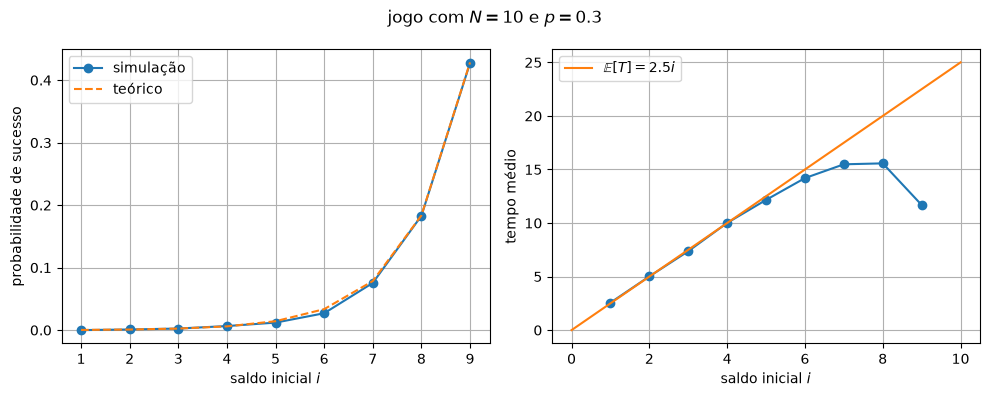

In [11]:
N = 10
p = 0.3
q = 1 - p
dados = []

for i in range(1, 10):
    prob, tempo, erro = simulacao_ruina(i, N, p, n_sim=2000)
    dados.append([i, prob, tempo, erro])

print(tabulate.tabulate(dados, headers=['Saldo inicial', 'Probabilidade de sucesso', 'Tempo médio', 'Erro'], tablefmt='github', floatfmt=['','.4f', '.2f', '.2e']))

# extrai dados da tabela para plotar graficos
i = [linha[0] for linha in dados]
prob = [linha[1] for linha in dados]
tempo = [linha[2] for linha in dados]
erro = [linha[3] for linha in dados]

prob_exata = [(1 - (q/p)**i_val) / (1 - (q/p)**N) for i_val in i]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle(r'jogo com $N=10$ e $p=0.3$')

ax1.plot(i, prob, 'o-', label='simulação')
ax1.plot(i, prob_exata, '--', label='teórico')
ax1.set_xlabel('saldo inicial $i$')
ax1.set_ylabel('probabilidade de sucesso')
ax1.legend()
ax1.grid()

ii = np.linspace(0, 10)
ax2.plot(i, tempo, 'o-')
ax2.plot(ii, ii/(q-p), label=r'$\mathbb{E}[T]=2.5i$')
ax2.set_xlabel('saldo inicial $i$')
ax2.set_ylabel('tempo médio')
ax2.grid()
ax2.legend()

plt.tight_layout()
plt.show()

### Conjectura da esperança para jogos assimétricos

Agora, como $p \neq q$, o jogo perde a simetria e o gráfico da esperança em função do saldo inicial se assemelha a uma reta para quase todo saldo, exceto para os valores mais próximos do objetivo. Neste caso, como $p<q$, é natural esperar que a jogatina leve mais tempo para acabar conforme o jogador começa com um saldo mais alto. Isso porque, embora ele esteja mais próximo do objetivo, a probabilidade de vitória em cada lançamento é menor que a de derrota e, uma vez que o jogador começa a perder, a probabilidade de atingir o objetivo é menor e a jogatina se arrasta no tempo. No entanto, ainda temos $\mathbb{E}_N[T]=0$, então o comportamento da função muda bastante perto dessa fronteira: se o jogador começa a jogatina com saldo inicial muito perto do objetivo, a chance de ele atingir o objetivo é alta e, portanto, o tempo de espera diminui.

Para estimar o comportamento linear da esperança, computamos a declividade $m$ da reta que passa pelos pontos (1, 2.59) e (2, 5.12) e obtemos $m=2.53$. Plotamos o gráfico da reta $\mathbb{E}[T]=2.5i$, que parece ajustar bem o conjunto de pontos até $i=7$. Notamos que $$\frac{1}{q-p} = 2.5,$$ então temos $$\mathbb{E}[T]=\frac{i}{q-p}$$ para pelo menos um subconjunto dos saldos iniciais.

In [6]:
m = (5.12 - 2.59)
print(m)

print(1/(q-p))

2.5300000000000002
2.5


### Simulação N=100, p=0.3, i=1:99

Com $N=100$, $p=0.3$, varremos $i$ de 1 a 99:

|   Saldo inicial |   Probabilidade de sucesso |   Tempo médio |     Erro |
|-----------------|----------------------------|---------------|----------|
|               1 |                     0.0000 |          2.54 | 2.12e-37 |
|               2 |                     0.0000 |          4.97 | 7.08e-37 |
|               3 |                     0.0000 |          7.32 | 1.86e-36 |
|               4 |                     0.0000 |          9.69 | 4.56e-36 |
|               5 |                     0.0000 |         12.42 | 1.09e-35 |
|               6 |                     0.0000 |         14.79 | 2.56e-35 |
|               7 |                     0.0000 |         17.22 | 5.98e-35 |
|               8 |                     0.0000 |         20.22 | 1.40e-34 |
|               9 |                     0.0000 |         22.52 | 3.27e-34 |
|              10 |                     0.0000 |         24.64 | 7.62e-34 |
|              11 |                     0.0000 |         27.73 | 1.78e-33 |
|           

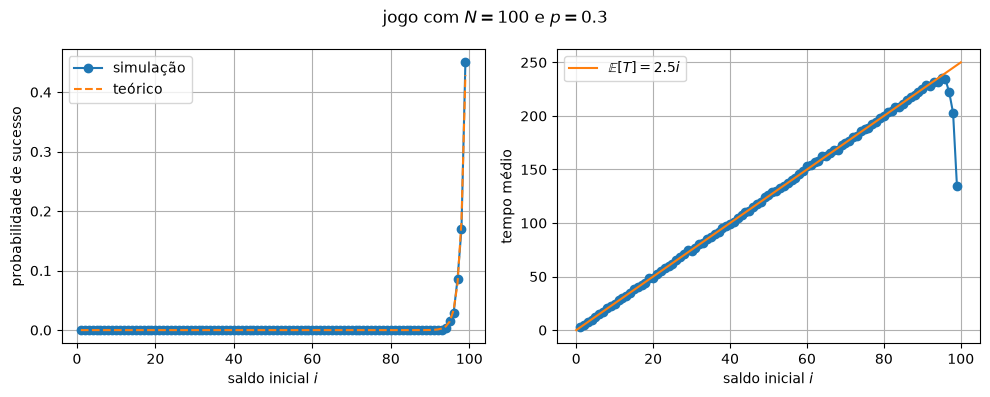

In [12]:
N = 100
p = 0.3
q = 1 - p

dados = []

for i in range(1, 100):
    prob, tempo, erro = simulacao_ruina(i, N, p)
    dados.append([i, prob, tempo, erro])

print(tabulate.tabulate(dados, headers=['Saldo inicial', 'Probabilidade de sucesso', 'Tempo médio', 'Erro'], tablefmt='github', floatfmt=['','.4f', '.2f', '.2e']))

# extrai dados da tabela para plotar graficos
i = [linha[0] for linha in dados]
prob = [linha[1] for linha in dados]
tempo = [linha[2] for linha in dados]
erro = [linha[3] for linha in dados]

prob_exata = [(1 - (q/p)**i_val) / (1 - (q/p)**N) for i_val in i]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle(r'jogo com $N=100$ e $p=0.3$')

ax1.plot(i, prob, 'o-', label='simulação')
ax1.plot(i, prob_exata, '--', label='teórico')
ax1.set_xlabel('saldo inicial $i$')
ax1.set_ylabel('probabilidade de sucesso')
ax1.legend()
ax1.grid()

ii = np.linspace(0, 100)
ax2.plot(i, tempo, 'o-')
ax2.plot(ii, ii/(q-p), label=r'$\mathbb{E}[T]=2.5i$')
ax2.set_xlabel('saldo inicial $i$')
ax2.set_ylabel('tempo médio')
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

### Simulação N=100, p=0.1, i=1:99

Colocando $p=0.1$, a probabilidade de vitória fica muito baixa.

|   Saldo inicial |   Probabilidade de sucesso |   Tempo médio |     Erro |
|-----------------|----------------------------|---------------|----------|
|               1 |                     0.0000 |          1.21 | 3.01e-95 |
|               2 |                     0.0000 |          2.53 | 3.01e-94 |
|               3 |                     0.0000 |          3.73 | 2.74e-93 |
|               4 |                     0.0000 |          4.98 | 2.47e-92 |
|               5 |                     0.0000 |          6.23 | 2.22e-91 |
|               6 |                     0.0000 |          7.51 | 2.00e-90 |
|               7 |                     0.0000 |          8.80 | 1.80e-89 |
|               8 |                     0.0000 |          9.95 | 1.62e-88 |
|               9 |                     0.0000 |         11.18 | 1.46e-87 |
|              10 |                     0.0000 |         12.42 | 1.31e-86 |
|              11 |                     0.0000 |         13.70 | 1.18e-85 |
|           

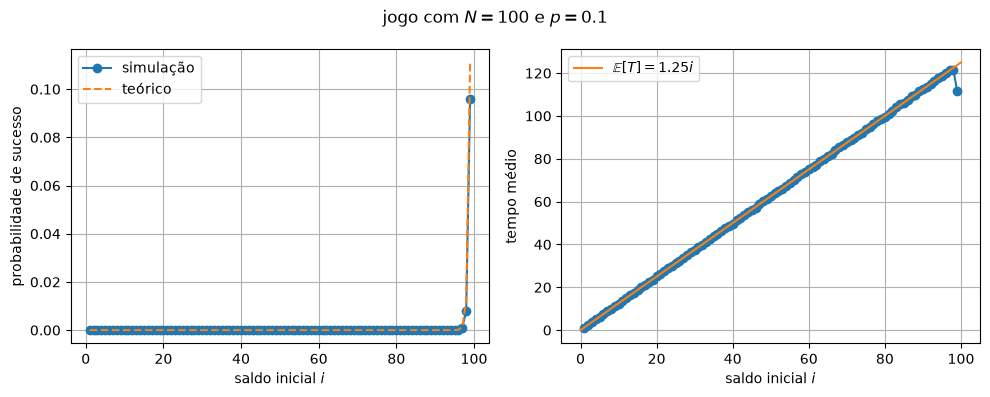

In [13]:
N = 100
p = 0.1
q = 1 - p

dados = []

for i in range(1, 100):
    prob, tempo, erro = simulacao_ruina(i, N=100, p=0.1)
    dados.append([i, prob, tempo, erro])

print(tabulate.tabulate(dados, headers=['Saldo inicial', 'Probabilidade de sucesso', 'Tempo médio', 'Erro'], tablefmt='github', floatfmt=['','.4f', '.2f', '.2e']))

# extrai dados da tabela para plotar graficos
i = [linha[0] for linha in dados]
prob = [linha[1] for linha in dados]
tempo = [linha[2] for linha in dados]
erro = [linha[3] for linha in dados]

prob_exata = [(1 - (q/p)**i_val) / (1 - (q/p)**N) for i_val in i]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle(r'jogo com $N=100$ e $p=0.1$')

ax1.plot(i, prob, 'o-', label='simulação')
ax1.plot(i, prob_exata, '--', label='teórico')
ax1.set_xlabel('saldo inicial $i$')
ax1.set_ylabel('probabilidade de sucesso')
ax1.legend()
ax1.grid()

ii = np.linspace(0, 100)
ax2.plot(i, tempo, 'o-')
ax2.plot(ii, ii/(q-p), label=r'$\mathbb{E}[T]=1.25i$')
ax2.set_xlabel('saldo inicial $i$')
ax2.set_ylabel('tempo médio')
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

In [9]:
m = 1/(q-p)
print(m)

1.25


### Relação de recorrência para a esperança


Podemos estabelecer uma relação de recorrência para $f_i = \mathbb{E}_t[T]$ no caso geral. Seja 

$$f_i=\mathbb{E}_i[T], \quad 1 \leq i \leq N-1,$$

o tempo esperado até o fim do jogo dado que o saldo inicial é $i$, com condições de fronteira $f_0 = f_N = 0$. Suponha que um jogador comece com saldo $i$, $1 \leq i \leq N-1$ e considere os eventos

* $A = \text{ganha a primeira rodada}$
* $B = \text{perde a primeira rodada}$

com probabilidades $P(A)=p$ e $P(B)=q$. É claro que $A$ e $B$ formam uma partição do espaço amostral para a primeira rodada, logo

$$\mathbb{E}_i[T] = p\mathbb{E}_i[T | A] + q\mathbb{E}_i[T | B].$$

Perceba que se o jogador ganha a primeira rodada, o saldo fica $i+1$ e o tempo aumenta em uma unidade. Então é como se o jogo recomeçasse com saldo $X_0=i+1$ e tempo de espera acrescido de 1, ou seja, 

$$\mathbb{E}_i[T | A] = \mathbb{E}_{i+1}[T] + 1 = f_{i+1} + 1.$$

Analogamente, caso ele perca, temos 

$$\mathbb{E}_i[T | B] = \mathbb{E}_{i-1}[T] + 1 = f_{i-1} + 1,$$

o que nos leva à seguinte relação de recorrência:

$$\begin{aligned}
    f_i &= p(f_{i+1} + 1) + q(f_{i-1} + 1) \\
    &= (p+q) + p f_{i+1} + q f_{i-1} \\
    &= 1 + p f_{i+1} + q f_{i-1}
\end{aligned}$$